Homework 2 - Perceptron and Backpropagation

In [1]:
import numpy as np
import matplotlib.pyplot as plt



Task 1 - Classical Perceptron Training

AND: epochs = 6 w = [1.  0.5] b = -1.0
AND: mistakes per epoch = [1, 3, 3, 2, 1, 0]
AND: final predictions = [0 0 0 1]
XOR: epochs = 20 w = [-0.5  0. ] b = 0.5
XOR: mistakes per epoch = [2, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
XOR: final predictions = [1 1 0 0]


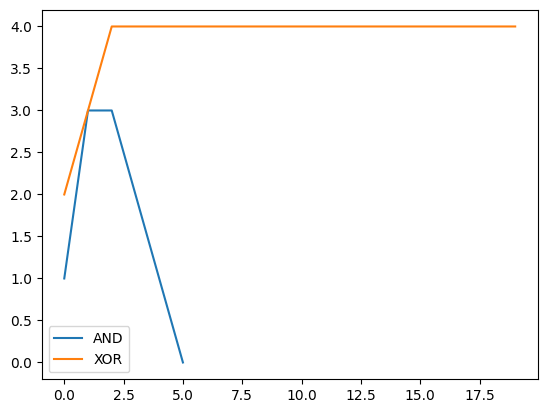

Wrong predictions for AND: []
Wrong predictions for XOR: [0 2]
Task 1 OK


In [2]:
X = np.array([
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0],
  ])
y_and = np.array([0, 0, 0, 1])
y_xor = np.array([0, 1, 1, 0])
def predict(X, w, b):
  # im not sure
  return np.where(np.dot(X, w) + b > 0, 1, 0)
  #
def train_perceptron(X, y, eta=0.5, max_epochs=20):
   w = np.zeros(2)
   b = 0.0
   mistakes_per_epoch = []
   for epoch in range(max_epochs):
      mistakes = 0
      for i in range(len(X)):
        # im not sure
        y_pred = predict(X[i], w, b)
        e = y[i] - y_pred
        if e != 0:
          mistakes += 1
          w = w + eta * e * X[i]
          b = b + eta * e
        #
      mistakes_per_epoch.append(mistakes)
      if mistakes == 0:
        break
   return w, b, mistakes_per_epoch
w_and, b_and, hist_and = train_perceptron(X, y_and)
w_xor, b_xor, hist_xor = train_perceptron(X, y_xor)
print("AND: epochs =", len(hist_and), "w =", w_and, "b =", b_and)
print("AND: mistakes per epoch =", hist_and)
print("AND: final predictions =", predict(X, w_and, b_and))

print("XOR: epochs =", len(hist_xor), "w =", w_xor, "b =", b_xor)
print("XOR: mistakes per epoch =", hist_xor)
print("XOR: final predictions =", predict(X, w_xor, b_xor))
# TODO: plot mistakes per epoch for both runs
# im not sure
plt.plot(hist_and, label='AND')
plt.plot(hist_xor, label='XOR')
plt.legend()
plt.show()
#
# TODO: report wrong predictions of each FINAL model
# im not sure
print("Wrong predictions for AND:", np.where(predict(X, w_and, b_and) != y_and)[0])
print("Wrong predictions for XOR:", np.where(predict(X, w_xor, b_xor) != y_xor)[0])
#
assert np.all(predict(X, w_and, b_and) == y_and)
print("Task 1 OK")

1. Why must the parameters be reset before the XOR run?
so that the perceptron actually learn, not choosing the right weights and bias from the beggining and starting with zeros. Also this way perceptron learns independently from and decisions
2. Why does success on AND not imply success on XOR? because one simple perceptron only can distinguish 2 classes by one straight line

3. Why can more epochs not overcome a single perceptron’s linear-boundary limitation on XOR?
because number of epochs is just the number of chances to update weidths and bias but it perceptron still can only distinguish classes using one straight line

4. Are online mistakes during an epoch always equal to the final model’s errors? Explain.
Not always. Because weights and bias change after every mistake

Task 2 - Hidden Unit over a Batch



In [3]:
x = np.array([0.5, 1.0, 1.5, 2.0])
y = np.array([2.0, 3.0, 4.0, 5.0])
params0 = np.array([0.5, 0.5, 1.0, 0.0])

def forward(params, x):
  w1, b1, w2, b2 = params
  z1 = w1 * x + b1
  h = np.maximum(0,z1)
  yhat = w2 * h + b2
  return z1, h, yhat
def batch_loss(params, x, y):
  z1, h, yhat = forward(params, x)
  assert yhat.shape == y.shape
  return np.mean((yhat - y) ** 2)

print(forward(params0, x))

(array([0.75, 1.  , 1.25, 1.5 ]), array([0.75, 1.  , 1.25, 1.5 ]), array([0.75, 1.  , 1.25, 1.5 ]))


dL/dw2 = 2/N*sum((yhati- yi)*hi)

dL/db2 = 2/N*sum(yhati- yi)

dL/dw1 = 2/N*sum(yhati- yi)*w2*1[z1,i>0]*x_i

dL/db1 = 2/N*sum(yhati- yi)*w2*1[z1,i>0]


In [4]:
def batch_gradients(params, x, y):
  w1, b1, w2, b2 = params
  z1, h, yhat = forward(params, x)
  N = len(x)
  g_yhat = 2*(yhat - y) / N
  g_w2 = np.sum(g_yhat * h)
  g_b2 = np.sum(g_yhat)
  g_h = g_yhat * w2
  g_z1 = g_h * (z1 > 0)
  g_w1 = np.sum(g_z1 * x)
  g_b1 = np.sum(g_z1)
  return np.array([g_w1, g_b1, g_w2, g_b2])


1. Where does the factor 1/𝑁 enter the gradients, and why?
It enters from the very beginning, g_yhat because we want to consider mean mistake, not summed.
2. Why do the shared-parameter gradients require a sum over the examples?
Because it's mathematical rule when differentiating sum. And also all of them are used to calculate prediction
3. What is the difference between the per-example vectors of shape (4,) and the returned parameter-gradient vector of shape (4,)?
Per-example has this size because we have 4 samples in batch and the returned parameter has this size because we have 4 parameters
4. Why is the output of this model not a probability?
because the output layer is linear and linear function can output any number not only from [0, 1]

Task 3 - Gradient Checking and Training

Why do we perturb one parameter at a
time, and what does .copy() prevent?
We want to see hos Loss changes if we change only one parameter at a time
We need copy() because we we could accidentally change initial params

What does 𝜀 control, and how does it differ from 𝜂?
𝜀 is just for checking but has no effect on model learning
 𝜂 is used in learning params = params - eta * gradient

Why must all gradients use the same parameter values before the update?
because gradient shows where loss increases the most in particular dot

Why does the loss history contain 201 values for 200 updates?
because we write loss at the very beggining before all updates

In [5]:
def numerical_gradient(fn, params, eps=1e-5):
  gradient = np.zeros_like(params, dtype=float)
  for j in range(len(params)):
    plus = params.copy()
    minus = params.copy()
    plus[j] += eps
    minus[j] -= eps
    gradient[j] = (fn(plus) - fn(minus)) / (2 * eps)
    # TODO: perturb coordinate j in each copy
    # TODO: assign the central-difference estimate ...
  return gradient
analytic = batch_gradients(params0, x, y)
numeric = numerical_gradient(
    lambda p: batch_loss(p, x, y), params0
    )
print("analytic:", analytic)
print("numeric :", numeric)
print("max absolute difference:", np.max(np.abs(analytic - numeric)))
assert np.max(np.abs(analytic - numeric)) < 1e-6
print("Task 3A OK")

analytic: [-6.875  -4.75   -5.8125 -4.75  ]
numeric : [-6.875  -4.75   -5.8125 -4.75  ]
max absolute difference: 8.662937034387141e-11
Task 3A OK


In [6]:
params = params0.copy()
eta = 0.01
loss_history = [batch_loss(params, x, y)]
for step in range(200):
  gradients = batch_gradients(params, x, y)
  params = params - eta * gradients
  loss_history.append(batch_loss(params, x, y))
print("final params:", params)
print("final loss :", loss_history[-1])
assert len(loss_history) == 201
assert loss_history[-1] < loss_history[0]
print("Task 3B OK")

final params: [1.21710839 0.65019193 1.54577988 0.1613669 ]
final loss : 0.004726306469450738
Task 3B OK


1. Which function performs backpropagation? Which statement updates the parameters?
batch_gradients(params, x, y)
params = params - eta * gradients
2. Why is updating a weight before finishing the backward pass incorrect?
because all 4 gradients have to be calculated with regards one point params.
3. Does the reduced loss on these four training examples demonstrate performance on unseen data? Explain.
No. Decreasing loss only tells that model began working better only with these 4 params, but it doesn't tell us anything about generalization.